In [1]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns
# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [14]:
df_RUS = df[df['job_country'] == 'Russia']
df_RUS

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
23,Machine Learning Engineer,"PhD position in computer science (NLP, finance)",Russia,via hh.ru,Full-time,False,Russia,2023-09-30 13:52:00,False,False,Russia,NaN,NaN,NaN,Грешнев Олег Владимирович,"[python, r]","{'programming': ['python', 'r']}"
284,Data Engineer,Data Engineer (DWH Arch),Anywhere,via hh.ru,Full-time,True,Russia,2023-12-27 13:38:19,True,False,Russia,NaN,NaN,NaN,ФЛАУВАУ,"[python, go, sql, airflow, kafka, spark, vue, ...","{'async': ['jira'], 'libraries': ['airflow', '..."
449,Data Engineer,Data Engineer,"Moscow, Russia",via hh.ru,Full-time,False,Russia,2023-02-07 13:37:23,True,False,Russia,NaN,NaN,NaN,Aviasales.ru,"[python, sql, scala, go, typescript, postgresq...","{'async': ['jira'], 'cloud': ['aws'], 'databas..."
541,Data Engineer,Data engineer в продукт МТС Маркетолог (Big Data),"Moscow, Russia",via hh.ru,Full-time,False,Russia,2023-03-02 13:18:53,False,False,Russia,NaN,NaN,NaN,"«МТС», IT","[python, sql, spark, kafka]","{'libraries': ['spark', 'kafka'], 'programming..."
605,Data Analyst,Data engineer / Data Scientist / Data Analyst,"Moscow, Russia",via hh.ru,Full-time,False,Russia,2023-10-13 14:10:51,False,False,Russia,NaN,NaN,NaN,СтандартПроект,"[python, sql, java, elasticsearch, airflow, ka...","{'databases': ['elasticsearch'], 'libraries': ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
782695,Machine Learning Engineer,Data Scientist / Machine Learning Engineer,"Krasnogorsk, Moscow Oblast, Russia",via hh.ru,Full-time,False,Russia,2023-01-17 07:15:29,False,False,Russia,NaN,NaN,NaN,Центр Методического Обеспечения Оптимизации Пр...,"[python, numpy, pandas, matplotlib, opencv, py...","{'libraries': ['numpy', 'pandas', 'matplotlib'..."
782772,Data Engineer,Data Engineer,"St Petersburg, Russia",via hh.ru,Full-time,False,Russia,2023-01-16 06:35:50,False,False,Russia,NaN,NaN,NaN,Сбер. IT,"[sql, c, t-sql, vba, c#, java, sql server, pos...","{'databases': ['sql server', 'postgresql'], 'p..."
782929,Software Engineer,DevOps Engineer,"Moscow, Russia",via Trabajo.org,Full-time,False,Russia,2023-10-23 06:44:34,True,False,Russia,NaN,NaN,NaN,Aston,"[sql, nosql, bash, vmware, windows, kubernetes...","{'cloud': ['vmware'], 'os': ['windows'], 'othe..."
783361,Data Scientist,Data инженер (YAPPY),Anywhere,via hh.ru,Full-time,True,Russia,2023-10-23 06:44:34,True,False,Russia,NaN,NaN,NaN,Rutube,"[sql, python, postgresql, airflow, hadoop, spa...","{'databases': ['postgresql'], 'libraries': ['a..."


In [12]:
df_skills = df_RUS.explode('job_skills')

df_skills[['job_title', 'job_skills']]

,job_title,job_skills
23,"PhD position in computer science (NLP, finance)",python
23,"PhD position in computer science (NLP, finance)",r
284,Data Engineer (DWH Arch),python
284,Data Engineer (DWH Arch),go
284,Data Engineer (DWH Arch),sql
...,...,...
785051,Старший инженер Hadoop,spark
785051,Старший инженер Hadoop,airflow
785051,Старший инженер Hadoop,kafka
785051,Старший инженер Hadoop,linux


In [19]:
df_skills_count = df_skills.groupby(['job_skills', 'job_title_short']).size()
print(df_skills_count)
df_skills_count = df_skills_count.reset_index(name='skill_count')
type(df_skills_count)

df_skills_count.sort_values(by= 'skill_count', ascending=False, inplace=True)
df_skills_count

job_skills  job_title_short     
airflow     Business Analyst         13
            Cloud Engineer            2
            Data Analyst             48
            Data Engineer           929
            Data Scientist          156
                                   ... 
zoom        Data Analyst              1
            Data Engineer             5
            Data Scientist            1
            Senior Data Engineer      2
            Software Engineer         3
Length: 881, dtype: int64


,job_skills,job_title_short,skill_count
751,sql,Data Engineer,1384
593,python,Data Engineer,1268
3,airflow,Data Engineer,929
290,hadoop,Data Engineer,739
725,spark,Data Engineer,709
...,...,...,...
876,zoom,Data Analyst,1
878,zoom,Data Scientist,1
845,vmware,Cloud Engineer,1
12,angular,Software Engineer,1


In [24]:
job_titles = df_skills_count['job_title_short'].unique().tolist()
job_titles = sorted(job_titles[:3])
job_titles

['Data Engineer', 'Data Scientist', 'Machine Learning Engineer']

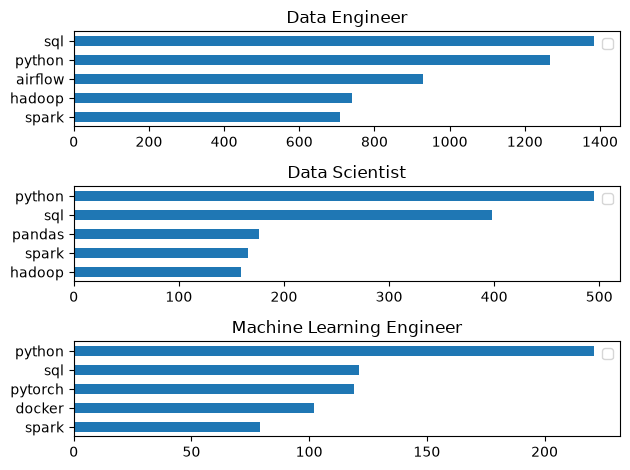

In [39]:
fig , ax = plt.subplots(len(job_titles), 1)

for i , job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count['job_title_short']== job_title].head(5)
    df_plot[::-1].plot(kind='barh', x= 'job_skills', y= 'skill_count', ax=ax[i], title= job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].legend('')
plt.tight_layout()    
  